# 04 · Delays

A delayed field is written as in the equations: `x(t - d)` in a drift is $x(t-d)$. Behind the scenes it is a convolution with the hard-delay kernel $\delta(t-d)$, whose frequency image $e^{-i\omega d}$ is not rational. Daedalus treats the two parts of the expansion differently:

* **Tree level** (the linear response and the Gaussian two-point function) is computed *exactly* from the delay-differential equation.
* **Loops** use a Padé approximant of $e^{-i\omega d}$ of order $n$. The order is chosen automatically: it is raised until the loop correction stops changing within the target tolerance, and the run reports what it did in `result['delay']`.

Distributed delays are kernels (`Kernel.delay(d) * Kernel.exponential(tau)` and so on) and a delay may also sit inside a nonlinear term. This tutorial computes one example of each; the [delay examples](../examples/SDE) compare them with simulations.

Run time: about one minute.

In [1]:
%matplotlib inline
try:
    preparser(False)   # Sage kernel: plain Python syntax and numbers in the cells below
except NameError:
    pass
import os, sys, time, warnings
import numpy as np
import matplotlib.pyplot as plt
# locate the repository root (the folder holding the 'api' package) from any working directory
_root = os.path.abspath('')
while _root != os.path.dirname(_root) and not os.path.isdir(os.path.join(_root, 'api')):
    _root = os.path.dirname(_root)
sys.path.insert(0, _root)
os.chdir(_root)
def ells(r):   # C(tau) per loop order (real parts), a list indexed by the loop order
    return [np.real(np.asarray(r['C_tau_by_ell'][l])) for l in sorted(r['C_tau_by_ell'])]
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

In [2]:
from api.sde import SDE
from api.noise import Gaussian
from api.delay import Kernel
from api import compute_cumulants

DELAY = {'tol': 1e-4}      # target relative change of the Padé loops between orders (default 1e-8)

def delay_report(r):
    d = r.get('delay') or {}
    keys = ('tree', 'approximant', 'n', 'orders_run', 'target_met', 'stop_reason')
    return {k: d.get(k) for k in keys if k in d}

## 1. A hard delay in a linear term

Delayed negative feedback with a cubic nonlinearity,

$$\dot x = -\mu x - c\,x(t-d) - \varepsilon x^3 + \xi, \qquad \langle\xi\xi\rangle = 2D\delta .$$

The delay makes the autocorrelation oscillate (the linear system has complex characteristic roots).

`delay=DELAY` sets the stopping rule of the automatic order: orders $n = 4, 8, 16, \dots$ are run until the loop correction changes by less than `tol` (relative) between orders. The default target, $10^{-8}$, is meant for reference results and can take minutes; $10^{-4}$ is ample for plots. The run reports the orders it tried, whether the target was met, and the estimated error (a `DelayOrderWarning` is shown when the cap `n_max` is reached first).

In [3]:
def delayed_ou(d=1.0):
    return (SDE('delayed OU')
            .parameter('mu', default=1.0, domain='positive').parameter('c', default=0.6)
            .parameter('d', default=d, domain='positive')
            .parameter('eps', default=0.1, domain='positive').parameter('D', default=0.5, domain='positive')
            .field('x')
            .drift('x', '-mu*x - c*x(t - d) - eps*x^3')
            .noise('xi', Gaussian(var='2*D'), couples={'x': 1}))
delayed_ou().show()
tau = np.linspace(-8, 8, 65)
t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    r = compute_cumulants(delayed_ou().build(), k=2, max_ell=1, external_fields=[('x', 1), ('x', 1)],
                          tau_grid=tau, parallel=False, verbose=False, delay=DELAY)
print(f"{time.time() - t0:.0f} s; delay report:", delay_report(r))
c = ells(r)

# SDE 'delayed OU' (ito)
.set_action_text('''
sum(
    xt[i]*(Dt*x[i] - (-mu*x[i] - c*Conv(delay_d, x[i]) - eps*x[i]^3))
    - (D*xt[i]^2)
    for i in pop)
''')
.equation(lhs='Dt*x[i] + mu*x[i]', rhs='-eps*x[i]^3 - c*((1))*(x[i])', population='pop')
# note: mean-field equation of 'x': linear term -mu*x[i] moved to the lhs.
2 s; delay report: {'tree': 'exact', 'approximant': 'pade', 'n': 8, 'orders_run': [4, 8], 'target_met': True, 'stop_reason': 'target 0.0001 met at n = 8 (estimate 6.68e-05)'}


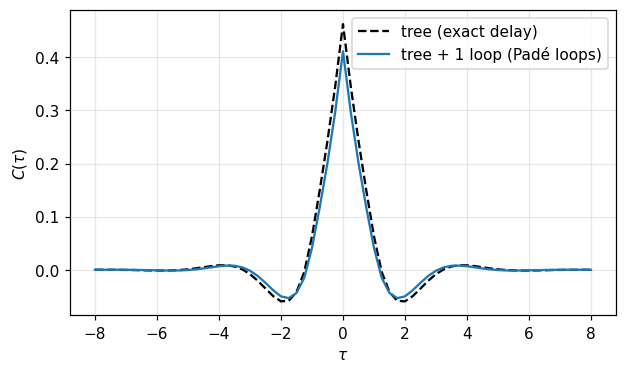

In [4]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(tau, c[0], 'k--', label='tree (exact delay)')
ax.plot(tau, c[0] + c[1], label='tree + 1 loop (Padé loops)')
ax.set_xlabel(r'$\tau$'); ax.set_ylabel(r'$C(\tau)$'); ax.legend(); plt.show()

The order can also be fixed: `delay={'order': n}`. Comparing two fixed orders shows how fast the Padé loops converge (the tree does not depend on the order: it is exact).

In [5]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    loops = {}
    for n in (2, 4, 8):
        rn = compute_cumulants(delayed_ou().build(), k=2, max_ell=1, external_fields=[('x', 1), ('x', 1)],
                               tau_grid=tau, parallel=False, verbose=False, delay={'order': n})
        loops[n] = ells(rn)[1]
for n in (2, 4):
    print(f"order {n}: max |loop - loop(order 8)| = {np.max(np.abs(loops[n] - loops[8])):.2e}"
          f"  (max |loop| = {np.max(np.abs(loops[8])):.2e})")

order 2: max |loop - loop(order 8)| = 3.24e-04  (max |loop| = 5.10e-02)
order 4: max |loop - loop(order 8)| = 2.74e-05  (max |loop| = 5.10e-02)


## 2. A distributed delay

Kernels compose: `Kernel.delay('d') * Kernel.exponential('tau')` is $g(t) = e^{-(t-d)/\tau}\Theta(t-d)/\tau$, a delayed low-pass filter. `define_kernel(name, delay='d', time_expr=...)` or `freq_image=...` gives the same.

4 s; delay report: {'tree': 'exact', 'approximant': 'pade', 'n': 8, 'orders_run': [4, 8], 'target_met': True, 'stop_reason': 'target 0.0001 met at n = 8 (estimate 6.65e-07)'}


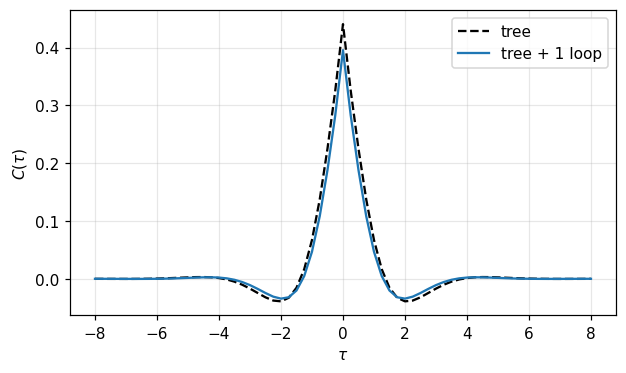

In [6]:
dist = (SDE('distributed delay')
        .parameter('mu', default=1.0, domain='positive').parameter('c', default=0.6)
        .parameter('d', default=0.5, domain='positive').parameter('tk', default=0.5, domain='positive')
        .parameter('eps', default=0.1, domain='positive').parameter('D', default=0.5, domain='positive')
        .define_kernel('g', kernel=Kernel.delay('d') * Kernel.exponential('tk'))
        .field('x')
        .drift('x', '-mu*x - c*Conv(g, x) - eps*x^3')
        .noise('xi', Gaussian(var='2*D'), couples={'x': 1}))
t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    rg = compute_cumulants(dist.build(), k=2, max_ell=1, external_fields=[('x', 1), ('x', 1)],
                           tau_grid=tau, parallel=False, verbose=False, delay=DELAY)
print(f"{time.time() - t0:.0f} s; delay report:", delay_report(rg))
cg = ells(rg)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(tau, cg[0], 'k--', label='tree'); ax.plot(tau, cg[0] + cg[1], label='tree + 1 loop')
ax.set_xlabel(r'$\tau$'); ax.set_ylabel(r'$C(\tau)$'); ax.legend(); plt.show()

## 3. A delay inside a nonlinear term

$$\dot x = -a x + b - c\,x\,x(t-d) + \xi .$$

The product $x\,x(t-d)$ is a vertex with one delayed leg. The mean field solves $a x^* + c x^{*2} = b$. A bare delay inside a product uses the strictly proper $[n-1/n]$ Padé approximant (the $[n/n]$ one has a $\delta$-like constant part); the run reports `approximant: 'pade_proper'`.

31 s; delay report: {'tree': 'exact', 'approximant': 'pade_proper', 'n': 8, 'orders_run': [4, 8], 'target_met': True, 'stop_reason': 'target 0.0001 met at n = 8 (estimate 1.07e-05)'}
saddle x* = [0.7320508075688773]


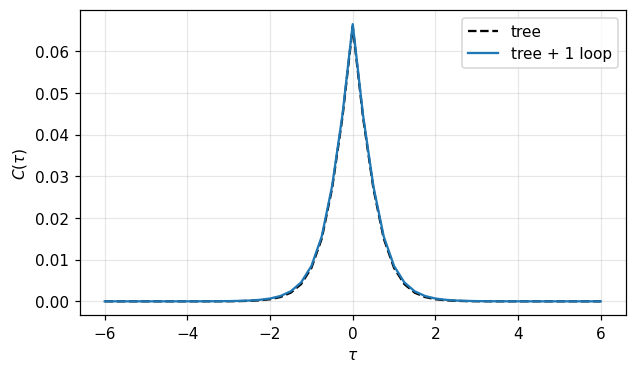

In [7]:
prod = (SDE('delayed product')
        .parameter('a', default=1.0).parameter('b', default=1.0).parameter('c', default=0.5)
        .parameter('d', default=0.5, domain='positive').parameter('D', default=0.1, domain='positive')
        .field('x')
        .drift('x', '-a*x + b - c*x*x(t - d)')
        .noise('xi', Gaussian(var='2*D'), couples={'x': 1}))
t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    rp = compute_cumulants(prod.build(), k=2, max_ell=1, external_fields=[('x', 1), ('x', 1)],
                           tau_grid=np.linspace(-6, 6, 49), parallel=False, verbose=False, delay=DELAY)
print(f"{time.time() - t0:.0f} s; delay report:", delay_report(rp))
print('saddle x* =', [float(v) for v in np.atleast_1d(rp['mf_values']['xstar'])])
cp = ells(rp)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(rp['tau_grid'], cp[0], 'k--', label='tree'); ax.plot(rp['tau_grid'], cp[0] + cp[1], label='tree + 1 loop')
ax.set_xlabel(r'$\tau$'); ax.set_ylabel(r'$C(\tau)$'); ax.legend(); plt.show()

## Notes

* Delays in point-process rates are written with kernels: `define_kernel('g', kernel=Kernel.delay('d') * Kernel.alpha('tg'))` and `Conv(g, n)` (see the delayed-alpha Hawkes example).
* `delay={...}` options: `order` (fixed order), `tree` (`'exact'` default, or `'pade'`), and the tolerance / budget knobs of the automatic order (`help(api.delay.resolve_options)`).
* `result['analysis']` records the approximation as a finding (`G3_DELAY_APPROXIMATED`) in the model report.